In [ ]:
import torch
import pandas as pd
import numpy
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("hotel_booking.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'name', 'email',
       'phone-number', 'credit_card'],
      dtype='object')

In [ ]:
df.shape

(119390, 36)

In [ ]:
df.hotel.unique()

array(['Resort Hotel', 'City Hotel'], dtype=object)

In [ ]:
df.required_car_parking_spaces

,required_car_parking_spaces
0,0
1,0
2,0
3,0
4,0
...,...
119385,0
119386,0
119387,0
119388,0


In [ ]:
df = df[['adr', 'hotel', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal','assigned_room_type',
       'required_car_parking_spaces']]

In [ ]:
df.shape

(119390, 14)

In [ ]:
df.isnull().sum()

,0
adr,0
hotel,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,4


In [ ]:
df = df.dropna()

In [ ]:
df.shape

(119386, 14)

In [ ]:
y = df.adr
X = df.drop(columns=['adr'])
X.head()

,hotel,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,assigned_room_type,required_car_parking_spaces
0,Resort Hotel,2015,July,27,1,0,0,2,0.0,0,BB,C,0
1,Resort Hotel,2015,July,27,1,0,0,2,0.0,0,BB,C,0
2,Resort Hotel,2015,July,27,1,0,1,1,0.0,0,BB,C,0
3,Resort Hotel,2015,July,27,1,0,1,1,0.0,0,BB,A,0
4,Resort Hotel,2015,July,27,1,0,2,2,0.0,0,BB,A,0


In [ ]:
X = pd.get_dummies(X, dtype='float32')

In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119386 entries, 0 to 119389
Data columns (total 40 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   arrival_date_year             119386 non-null  int64  
 1   arrival_date_week_number      119386 non-null  int64  
 2   arrival_date_day_of_month     119386 non-null  int64  
 3   stays_in_weekend_nights       119386 non-null  int64  
 4   stays_in_week_nights          119386 non-null  int64  
 5   adults                        119386 non-null  int64  
 6   children                      119386 non-null  float64
 7   babies                        119386 non-null  int64  
 8   required_car_parking_spaces   119386 non-null  int64  
 9   hotel_City Hotel              119386 non-null  float32
 10  hotel_Resort Hotel            119386 non-null  float32
 11  arrival_date_month_April      119386 non-null  float32
 12  arrival_date_month_August     119386 non-null  fl

In [ ]:
X.shape

(119386, 40)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=2,
    tree_method="hist",
    device="cuda",
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=100,
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)


[0]	validation_0-rmse:47.46585
[100]	validation_0-rmse:26.61571
[200]	validation_0-rmse:24.83022
[300]	validation_0-rmse:24.22025
[400]	validation_0-rmse:23.88203
[500]	validation_0-rmse:23.63940
[600]	validation_0-rmse:23.46329
[700]	validation_0-rmse:23.35649
[800]	validation_0-rmse:23.27926
[900]	validation_0-rmse:23.19901
[1000]	validation_0-rmse:23.14144
[1100]	validation_0-rmse:23.09907
[1200]	validation_0-rmse:23.05854
[1300]	validation_0-rmse:23.04458
[1400]	validation_0-rmse:23.01929
[1500]	validation_0-rmse:23.00873
[1600]	validation_0-rmse:23.00545
[1700]	validation_0-rmse:22.98426
[1790]	validation_0-rmse:22.98902


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device='cuda', early_stopping_rounds=100,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=3, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2000,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred = model.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 15.473229654888701
MSE: 528.1294798344909
R2 Score: 0.7732106235494677


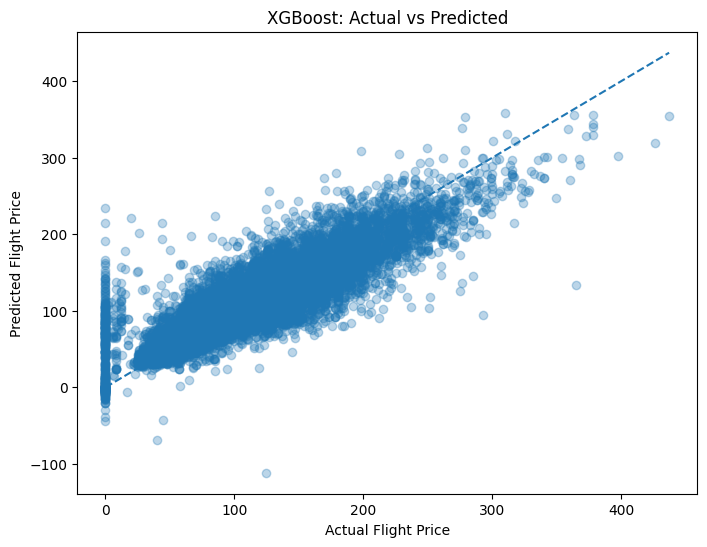

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("XGBoost: Actual vs Predicted")

plt.show()

In [ ]:
# !pip install catboost
from catboost import CatBoostRegressor
model = CatBoostRegressor(
    task_type="GPU",
    iterations=500,
    devices="0"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Learning rate set to 0.111023
0:	learn: 49.0204556	total: 4.21ms	remaining: 2.1s
1:	learn: 47.2355096	total: 7.33ms	remaining: 1.82s
2:	learn: 45.7861449	total: 10.5ms	remaining: 1.73s
3:	learn: 44.5054973	total: 13.5ms	remaining: 1.68s
4:	learn: 43.5333684	total: 16.8ms	remaining: 1.66s
5:	learn: 42.3074205	total: 19.8ms	remaining: 1.63s
6:	learn: 41.5393804	total: 22.8ms	remaining: 1.61s
7:	learn: 40.5319799	total: 25.8ms	remaining: 1.59s
8:	learn: 39.8277672	total: 28.9ms	remaining: 1.57s
9:	learn: 39.2904419	total: 32ms	remaining: 1.57s
10:	learn: 38.6766866	total: 35ms	remaining: 1.56s
11:	learn: 38.2219159	total: 38.2ms	remaining: 1.55s
12:	learn: 37.8329629	total: 41.2ms	remaining: 1.54s
13:	learn: 37.4394481	total: 44.2ms	remaining: 1.53s
14:	learn: 36.9838173	total: 47.3ms	remaining: 1.53s
15:	learn: 36.6258153	total: 50.3ms	remaining: 1.52s
16:	learn: 36.3448106	total: 53.4ms	remaining: 1.52s
17:	learn: 36.0771511	total: 56.4ms	remaining: 1.51s
18:	learn: 35.8749626	total: 59

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 17.325030047042418
MSE: 595.3581948077624
R2 Score: 0.7443412668282012


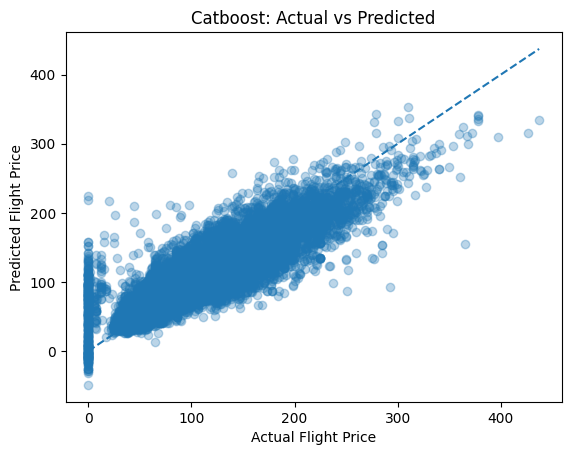

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")
plt.title("Catboost: Actual vs Predicted")

plt.show()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

import numpy as np
# import torch

# scale target too (train stats only)
y_mean = y_train.mean()
y_std = y_train.std()
y_train = (y_train - y_mean) / y_std

X_train = torch.tensor(
    np.asarray(X_train, dtype=np.float32),
    dtype=torch.float32
).to(device)

X_test = torch.tensor(
    np.asarray(X_test, dtype=np.float32),
    dtype=torch.float32
).to(device)

y_train = torch.tensor(
    y_train.to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)

y_test = torch.tensor(
    y_test.to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)

In [ ]:
X.shape

(119386, 40)

In [ ]:
from torch import nn

class BhoirNetwork(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(40, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
model = BhoirNetwork(X_train.shape[1]).to(device)

In [ ]:
criterion = nn.HuberLoss(delta=1.0)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

In [ ]:
epochs = 1000

for epoch in range(epochs):

    # Training mode
    model.train()

    # Forward propagation
    y_pred = model(X_train)

    # Calculate loss
    loss = criterion(y_pred, y_train)

    # Clear previous gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights and bias
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_pred = model(X_test)
        val_loss = criterion(val_pred, y_test)

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Val Loss: {val_loss.item():.4f}"
        )

Epoch [100/1000] Train Loss: 0.1176 Val Loss: 101.4265
Epoch [200/1000] Train Loss: 0.1056 Val Loss: 101.4090
Epoch [300/1000] Train Loss: 0.0956 Val Loss: 101.4162
Epoch [400/1000] Train Loss: 0.0890 Val Loss: 101.4086
Epoch [500/1000] Train Loss: 0.0847 Val Loss: 101.4151
Epoch [600/1000] Train Loss: 0.0820 Val Loss: 101.4140
Epoch [700/1000] Train Loss: 0.0793 Val Loss: 101.4067
Epoch [800/1000] Train Loss: 0.0770 Val Loss: 101.3981
Epoch [900/1000] Train Loss: 0.0758 Val Loss: 101.4266
Epoch [1000/1000] Train Loss: 0.0753 Val Loss: 101.3905


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

model.eval()

with torch.no_grad():
    y_pred = model(X_test)

actual = y_test.cpu().numpy().flatten()
predicted = y_pred.cpu().numpy().flatten()

mse = mean_squared_error(actual, predicted)
mae = mean_absolute_error(actual, predicted)
r2 = r2_score(actual, predicted)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)
print("RMSE:", mse ** 0.5)

MSE: 12636.66015625
MAE: 101.88919830322266
R2 Score: -4.4264349937438965
RMSE: 112.41290031064051


In [ ]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

target = 'adr'
df_h = df[(df[target] > 0) & (df[target] < 1000)].copy()

leaky = ['reservation_status', 'reservation_status_date']
Xh = df_h.drop(columns=[target] + [c for c in leaky if c in df_h.columns])
yh = df_h[target]

# extra features
Xh['total_nights'] = Xh['stays_in_weekend_nights'] + Xh['stays_in_week_nights']
Xh['total_guests'] = Xh['adults'] + Xh['children'].fillna(0) + Xh['babies']

# agent/company are IDs stored as floats with NaN -> treat as categories
for c in ['agent', 'company']:
    if c in Xh.columns:
        Xh[c] = Xh[c].fillna(0).astype(int).astype(str)

Xh['children'] = Xh['children'].fillna(0)

# month is seasonal: add cyclic encoding as well
if 'arrival_date_month' in Xh.columns:
    months = ['January','February','March','April','May','June','July',
              'August','September','October','November','December']
    m = Xh['arrival_date_month'].map({k: i for i, k in enumerate(months)})
    Xh['month_sin'] = np.sin(2 * np.pi * m / 12)
    Xh['month_cos'] = np.cos(2 * np.pi * m / 12)

# one-hot, explicit columns (rare values grouped so it doesn't explode)
cat_cols = Xh.select_dtypes(exclude='number').columns.tolist()
for c in cat_cols:
    top = Xh[c].value_counts().index[:30]
    Xh[c] = Xh[c].where(Xh[c].isin(top), 'other')

Xh = pd.get_dummies(Xh, columns=cat_cols, dtype='float32')

Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)

scaler = StandardScaler()
Xh_train_s = scaler.fit_transform(Xh_train)
Xh_test_s = scaler.transform(Xh_test)

y_log = np.log1p(yh_train)
y_mean = y_log.mean()
y_std = y_log.std()

Xtr = torch.tensor(np.asarray(Xh_train_s, dtype=np.float32), dtype=torch.float32).to(device)
Xte = torch.tensor(np.asarray(Xh_test_s, dtype=np.float32), dtype=torch.float32).to(device)

ytr = torch.tensor(
    ((y_log - y_mean) / y_std).to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)

yte = torch.tensor(
    yh_test.to_numpy(dtype=np.float32),
    dtype=torch.float32
).reshape(-1, 1).to(device)  # real prices

Xtr.shape

torch.Size([93943, 297])

In [ ]:
class BhoirNetwork(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
model = BhoirNetwork(Xtr.shape[1]).to(device)

criterion = nn.HuberLoss(delta=1.0)

epochs = 80
batch_size = 512
steps_per_epoch = (len(Xtr) + batch_size - 1) // batch_size

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=3e-3,
    epochs=epochs,
    steps_per_epoch=steps_per_epoch
)

In [ ]:
import copy

def predict(Xin):
    model.eval()
    with torch.no_grad():
        out = model(Xin) * y_std + y_mean
        return torch.expm1(out).cpu().numpy()

best_r2 = -1
best_state = None
true = yte.cpu().numpy()

for epoch in range(epochs):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    total = 0

    for i in range(0, len(Xtr), batch_size):
        idx = perm[i:i + batch_size]
        if len(idx) < 2:  # BatchNorm needs >1 sample
            continue

        optimizer.zero_grad()
        loss = criterion(model(Xtr[idx]), ytr[idx])
        loss.backward()
        optimizer.step()
        scheduler.step()

        total += loss.item() * len(idx)

    pred = predict(Xte)
    r2 = r2_score(true, pred)
    if r2 > best_r2:
        best_r2 = r2
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 5 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:2d} | train loss {total / len(Xtr):.4f} | "
              f"R2 {r2:.4f} | MAE {mean_absolute_error(true, pred):,.2f}")

model.load_state_dict(best_state)
pred = predict(Xte)
print(f"best -> R2 {r2_score(true, pred):.4f} | MAE {mean_absolute_error(true, pred):,.2f}")

epoch  0 | train loss 0.2014 | R2 0.7611 | MAE 14.92
epoch  5 | train loss 0.0678 | R2 0.8535 | MAE 10.97
epoch 10 | train loss 0.0573 | R2 0.8789 | MAE 9.84
epoch 15 | train loss 0.0526 | R2 0.9017 | MAE 8.90
epoch 20 | train loss 0.0482 | R2 0.9057 | MAE 8.67
epoch 25 | train loss 0.0444 | R2 0.9097 | MAE 8.21
epoch 30 | train loss 0.0407 | R2 0.9152 | MAE 7.97
epoch 35 | train loss 0.0374 | R2 0.9152 | MAE 7.92
epoch 40 | train loss 0.0350 | R2 0.9161 | MAE 7.75
epoch 45 | train loss 0.0321 | R2 0.9173 | MAE 7.81
epoch 50 | train loss 0.0297 | R2 0.9206 | MAE 7.52
epoch 55 | train loss 0.0274 | R2 0.9223 | MAE 7.32
epoch 60 | train loss 0.0257 | R2 0.9221 | MAE 7.30
epoch 65 | train loss 0.0240 | R2 0.9233 | MAE 7.25
epoch 70 | train loss 0.0230 | R2 0.9245 | MAE 7.10
epoch 75 | train loss 0.0225 | R2 0.9249 | MAE 7.10
epoch 79 | train loss 0.0224 | R2 0.9249 | MAE 7.09
best -> R2 0.9249 | MAE 7.10


In [ ]:
torch.save(
    model.state_dict(),
    "hotel_price.pth"
)